
Files loaded:
Gz: 200 epochs
Txx: 227 epochs
Txy: 133 epochs
Txz: 189 epochs
Tyy: 120 epochs
Tyz: 219 epochs
Tzz: 179 epochs


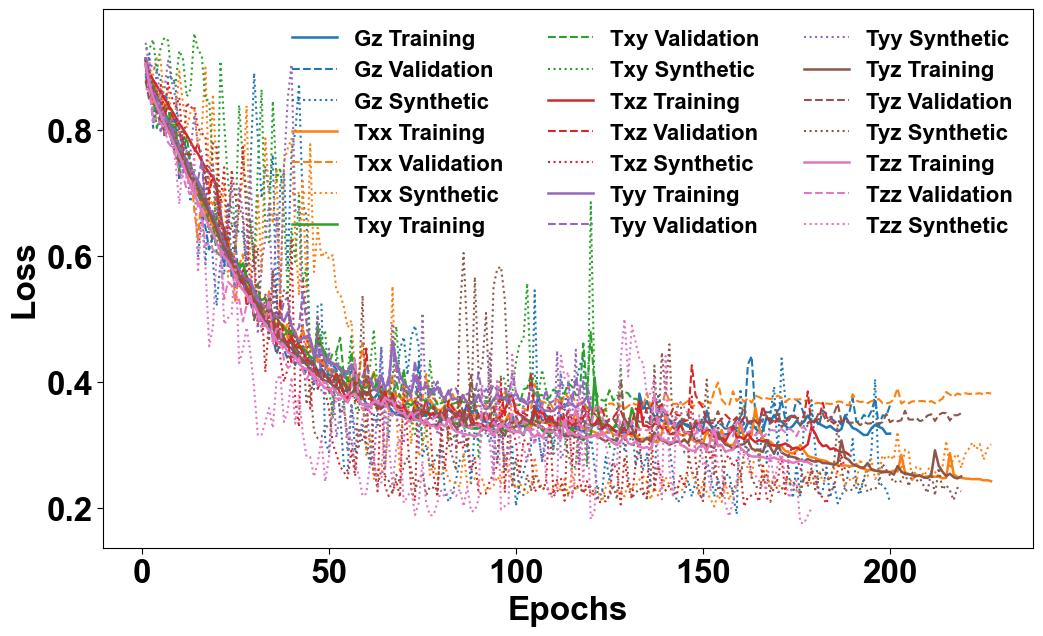

Saved: C:\Users\Rahul Maurya\OneDrive\Desktop\Rahul_MTP\CNN_Method\two_prisms_cnn\Convergence_Curve_Combined_all_Components\All_7_Components_Convergence_Curves.png

Saved:
C:\Users\Rahul Maurya\OneDrive\Desktop\Rahul_MTP\CNN_Method\two_prisms_cnn\Convergence_Curve_Combined_all_Components\All_7_Components_Convergence_Curves.png


In [22]:
# =====================================================================
# ALL 7 TENSOR-COMPONENT CONVERGENCE CURVES
# =====================================================================
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from PIL import Image, ImageChops
from pathlib import Path

# =====================================================================
# GLOBAL PUBLICATION SETTINGS
# =====================================================================
BG=AX="white"; TC="black"; DPI=600
mpl.rcParams.update({
    "font.family":"Arial","font.size":24,
    "axes.labelsize":24,"axes.titlesize":24,"xtick.labelsize":24,"ytick.labelsize":24,
    "legend.fontsize":16,"figure.facecolor":"white",
    "axes.facecolor":"white","savefig.dpi":600,
    "savefig.facecolor":"white","axes.edgecolor":"black",
    "axes.linewidth":.8,"xtick.color":"black","ytick.color":"black",
    "text.color":"black","axes.labelcolor":"black",
    "ps.fonttype":42,"font.weight":"bold","axes.labelweight":"bold",
    "axes.titleweight":"bold"
})
def save_fig(fig,filename,tight=True):
    kw={"dpi":600,"facecolor":BG,"pad_inches":0}
    if tight:kw["bbox_inches"]="tight"
    fig.savefig(filename,**kw)
    plt.show()
    plt.close(fig)
    crop_white_margin(filename,padding=0)
    print("Saved:",filename)

def crop_white_margin(filename,padding=0):
    img=Image.open(filename).convert("RGB")
    bbox=ImageChops.difference(img,Image.new("RGB",img.size,"white")).getbbox()
    if bbox:
        x0,y0,x1,y1=bbox
        img.crop((max(0,x0-padding),max(0,y0-padding),
                  min(img.width,x1+padding),min(img.height,y1+padding))
                ).save(filename,dpi=(DPI,DPI))
# ---------------------------------------------------------------------
# DATA DIRECTORY AND COMPONENTS
# ---------------------------------------------------------------------
DATA_DIR=Path(r"C:\Users\Rahul Maurya\OneDrive\Desktop\Rahul_MTP\CNN_Method\two_prisms_cnn\Convergence_Curve_Combined_all_Components")
components=["Gz","Txx","Txy","Txz","Tyy","Tyz","Tzz"]
files={c:DATA_DIR/f"{c.lower()}_Conver_Curve_Data.xlsx" for c in components}
# ---------------------------------------------------------------------
# LOAD AND CHECK ALL FILES
# ---------------------------------------------------------------------
data={}; required=["Epoch","Training Loss","Validation Loss","Synthetic Loss"]
for c,f in files.items():
    if not f.exists():
        print(f"WARNING: {f.name} not found"); continue
    df=pd.read_excel(f)
    if not all(col in df.columns for col in required):
        raise ValueError(f"{f.name} does not contain the required columns.")
    data[c]=df
    
print("\nFiles loaded:")
for c,df in data.items(): print(f"{c}: {len(df)} epochs")
# ---------------------------------------------------------------------
# PLOT ALL CONVERGENCE CURVES
# ---------------------------------------------------------------------
fig,ax=plt.subplots(figsize=(12,7)); colors=plt.cm.tab10.colors

for i,c in enumerate(components):
    if c not in data: continue
    df=data[c]; col=colors[i]
    ax.plot(df["Epoch"],df["Training Loss"],color=col,lw=1.8,label=f"{c} Training")
    ax.plot(df["Epoch"],df["Validation Loss"],color=col,ls="--",lw=1.5,label=f"{c} Validation")
    ax.plot(df["Epoch"],df["Synthetic Loss"],color=col,ls=":",lw=1.5,label=f"{c} Synthetic")
# ---------------------------------------------------------------------
# AXIS, LEGEND AND STYLE
# ---------------------------------------------------------------------
ax.set_xlabel("Epochs"); ax.set_ylabel("Loss")
ax.tick_params(axis="both",direction="out",width=.8,length=4)
ax.grid(False)
for s in ax.spines.values(): s.set_linewidth(.8)
ax.legend(loc="best",ncol=3,frameon=0.0)

# ---------------------------------------------------------------------
# SAVE FIGURE
# ---------------------------------------------------------------------
output=DATA_DIR/"All_7_Components_Convergence_Curves.png"
save_fig(fig,output)
print(f"\nSaved:\n{output}")